In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [51]:
from sklearn.datasets import load_iris

In [52]:
iris = load_iris()

In [53]:
from sklearn.model_selection import train_test_split

In [54]:
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size= 0.2, random_state= 42)

In [55]:
df = pd.DataFrame(data= X_train, columns= iris.feature_names)

In [56]:
df['target'] = y_train

In [57]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,4.6,3.6,1.0,0.2,0
1,5.7,4.4,1.5,0.4,0
2,6.7,3.1,4.4,1.4,1
3,4.8,3.4,1.6,0.2,0
4,4.4,3.2,1.3,0.2,0


In [58]:
def row_sampling(df, percentage):
    return df.sample(int((df.shape[0] * percentage) / 100), replace = True)

In [59]:
row_sampling(df, 10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
4,4.4,3.2,1.3,0.2,0
89,5.2,2.7,3.9,1.4,1
95,5.6,3.0,4.1,1.3,1
114,5.4,3.4,1.7,0.2,0
50,6.4,2.7,5.3,1.9,2
10,5.8,2.7,5.1,1.9,2
74,6.3,3.4,5.6,2.4,2
103,6.7,3.1,5.6,2.4,2
20,5.7,2.9,4.2,1.3,1
6,6.4,3.2,4.5,1.5,1


In [61]:
import random
def column_sampling(df, percentage):
    columns = random.sample(df.columns.to_list()[:-1], int(percentage * (df.shape[1] - 1) / 100))
    new_df = df[columns]
    new_df['target'] = df['target']
    return new_df

In [65]:
column_sampling(df, 50)

C:\Users\gpava\AppData\Local\Temp\ipykernel_16916\2569538195.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


,petal length (cm),sepal length (cm),target
0,1.0,4.6,0
1,1.5,5.7,0
2,4.4,6.7,1
3,1.6,4.8,0
4,1.3,4.4,0
...,...,...,...
115,4.0,6.1,1
116,4.5,4.9,2
117,1.2,5.8,0
118,4.0,5.8,1


In [66]:
def combined_sampling(df, row_percent, col_percent):
    new_df = row_sampling(df, row_percent)
    new_df = column_sampling(new_df, col_percent)
    return new_df

In [68]:
combined_sampling(df, 10, 50)

C:\Users\gpava\AppData\Local\Temp\ipykernel_16916\2569538195.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


,sepal width (cm),petal length (cm),target
76,3.0,5.5,2
0,3.6,1.0,0
62,2.7,5.1,1
58,3.5,1.6,0
18,3.0,4.4,1
80,2.8,4.6,1
102,3.6,1.4,0
41,4.2,1.4,0
20,2.9,4.2,1
102,3.6,1.4,0


In [69]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [70]:
from sklearn.metrics import accuracy_score

In [71]:
dt1 = DecisionTreeClassifier(max_depth = 3)
dt2 = DecisionTreeClassifier(max_depth = 3)
dt3 = DecisionTreeClassifier(max_depth = 3)

In [72]:
data1 = row_sampling(df, 50)
data2 = row_sampling(df, 50)
data3 = row_sampling(df, 50)

In [73]:
dt1.fit(data1.iloc[:, :-1], data1.iloc[:, -1])
dt2.fit(data2.iloc[:, :-1], data2.iloc[:, -1])
dt3.fit(data3.iloc[:, :-1], data3.iloc[:, -1])

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


[Text(0.6, 0.875, 'petal width (cm) <= 1.55\ngini = 0.64\nsamples = 60\nvalue = [12, 24, 24]\nclass = versicolor'),
 Text(0.4, 0.625, 'petal width (cm) <= 0.75\ngini = 0.499\nsamples = 38\nvalue = [12, 24, 2]\nclass = versicolor'),
 Text(0.5, 0.75, 'True  '),
 Text(0.2, 0.375, 'gini = 0.0\nsamples = 12\nvalue = [12, 0, 0]\nclass = setosa'),
 Text(0.6, 0.375, 'petal length (cm) <= 4.95\ngini = 0.142\nsamples = 26\nvalue = [0, 24, 2]\nclass = versicolor'),
 Text(0.4, 0.125, 'gini = 0.0\nsamples = 24\nvalue = [0, 24, 0]\nclass = versicolor'),
 Text(0.8, 0.125, 'gini = 0.0\nsamples = 2\nvalue = [0, 0, 2]\nclass = virginica'),
 Text(0.8, 0.625, 'gini = 0.0\nsamples = 22\nvalue = [0, 0, 22]\nclass = virginica'),
 Text(0.7, 0.75, '  False')]

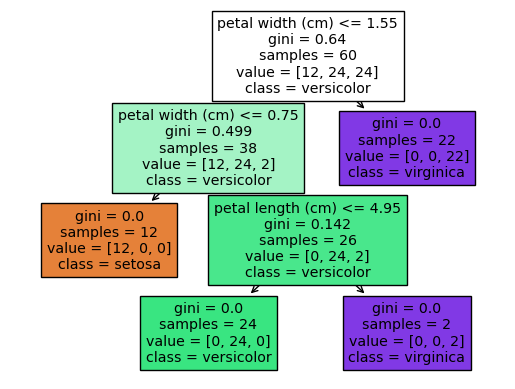

In [74]:
plot_tree(dt1, filled= True, feature_names= iris.feature_names, class_names= iris.target_names)

[Text(0.4, 0.8333333333333334, 'petal length (cm) <= 2.5\ngini = 0.66\nsamples = 60\nvalue = [24, 18, 18]\nclass = setosa'),
 Text(0.2, 0.5, 'gini = 0.0\nsamples = 24\nvalue = [24, 0, 0]\nclass = setosa'),
 Text(0.30000000000000004, 0.6666666666666667, 'True  '),
 Text(0.6, 0.5, 'petal width (cm) <= 1.65\ngini = 0.5\nsamples = 36\nvalue = [0, 18, 18]\nclass = versicolor'),
 Text(0.5, 0.6666666666666667, '  False'),
 Text(0.4, 0.16666666666666666, 'gini = 0.0\nsamples = 18\nvalue = [0, 18, 0]\nclass = versicolor'),
 Text(0.8, 0.16666666666666666, 'gini = 0.0\nsamples = 18\nvalue = [0, 0, 18]\nclass = virginica')]

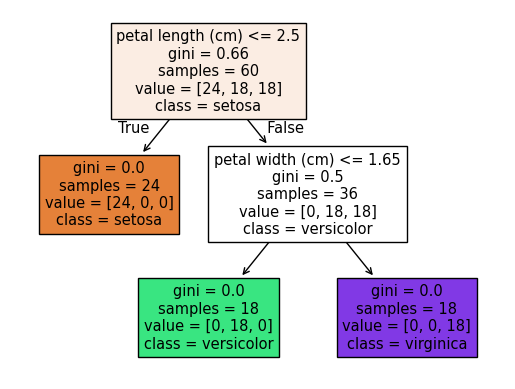

In [75]:
plot_tree(dt2, filled= True, feature_names= iris.feature_names, class_names= iris.target_names)

[Text(0.375, 0.875, 'petal length (cm) <= 2.45\ngini = 0.666\nsamples = 60\nvalue = [21, 20, 19]\nclass = setosa'),
 Text(0.25, 0.625, 'gini = 0.0\nsamples = 21\nvalue = [21, 0, 0]\nclass = setosa'),
 Text(0.3125, 0.75, 'True  '),
 Text(0.5, 0.625, 'petal width (cm) <= 1.65\ngini = 0.5\nsamples = 39\nvalue = [0, 20, 19]\nclass = versicolor'),
 Text(0.4375, 0.75, '  False'),
 Text(0.25, 0.375, 'sepal width (cm) <= 2.25\ngini = 0.095\nsamples = 20\nvalue = [0, 19, 1]\nclass = versicolor'),
 Text(0.125, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]\nclass = virginica'),
 Text(0.375, 0.125, 'gini = 0.0\nsamples = 19\nvalue = [0, 19, 0]\nclass = versicolor'),
 Text(0.75, 0.375, 'sepal width (cm) <= 3.15\ngini = 0.1\nsamples = 19\nvalue = [0, 1, 18]\nclass = virginica'),
 Text(0.625, 0.125, 'gini = 0.0\nsamples = 16\nvalue = [0, 0, 16]\nclass = virginica'),
 Text(0.875, 0.125, 'gini = 0.444\nsamples = 3\nvalue = [0, 1, 2]\nclass = virginica')]

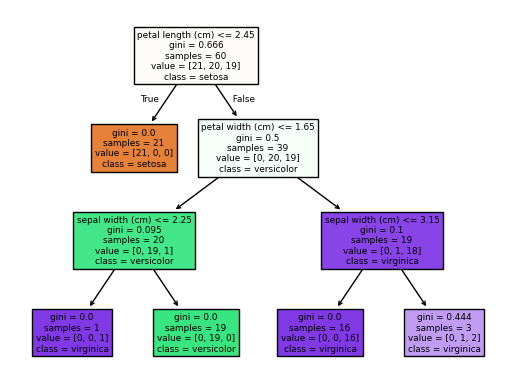

In [76]:
plot_tree(dt3, filled= True, feature_names= iris.feature_names, class_names= iris.target_names)

In [91]:
y1= dt1.predict(X_test)
y2 = dt2.predict(X_test)
y3 = dt3.predict(X_test)

C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [92]:
np.vstack((y1, y2, y3))

array([[1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 2, 2, 1, 1, 2, 0, 2,
        0, 2, 2, 2, 2, 2, 0, 0],
       [1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
        0, 2, 2, 2, 2, 2, 0, 0],
       [1, 0, 2, 1, 1, 0, 1, 2, 2, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
        0, 2, 2, 2, 2, 2, 0, 0]])

In [93]:
from scipy.stats import mode

In [94]:
mode_values = mode(np.vstack((y1, y2, y3)), axis= 0).mode

In [95]:
mode_values

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0])

In [97]:
accuracy_score(y_test, mode_values)

1.0

In [98]:
accuracy_score(y_test, y1)

0.9666666666666667

In [99]:
accuracy_score(y_test, y2)

1.0

In [100]:
accuracy_score(y_test, y3)

0.9666666666666667